# Considering a Future

*The Mathematics of Machine Intelligence · Chapter 17*

Score a plan inside a model, price a look, and see what a search cannot weigh.

These pages illustrate the mathematics. Read the saved figures and calculations in order, or open [the interactive browser edition](reader.html) to change the examples. No code editing is needed. Every figure is computed from the chapter's own equations or from a disclosed simulation; a simulation is not a measurement, and the mathematics of a brain is a model.

Ask what the model holds, what the score ranks, and what each look costs. Work a value or a route score by hand on a small map before trusting a search, check whether a first look can look worthless while two looks pay, and ask a planner to list the constraints it assumed so that missing ones show. A search can only weigh the futures its model contains.

<details><summary>Reproducing these calculations</summary>

The optional calculation cells use Python with NumPy and Matplotlib. All inputs, random seeds and functions are included in this file. The figures below are saved, so running these cells is optional.

</details>

In [1]:
import io
import math
import re
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from cycler import cycler
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 11, 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#7d8588', 'axes.labelcolor': '#172a3b', 'text.color': '#172a3b', 'xtick.color': '#52606b', 'ytick.color': '#52606b', 'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white', 'grid.alpha': 0.2, 'lines.linewidth': 2, 'svg.fonttype': 'path', 'axes.unicode_minus': False})
plt.rcParams['axes.prop_cycle'] = cycler(color=['#136f75', '#b77518', '#334c72', '#aa4e37', '#677341'])

def clean_display_text(text):
    """Remove signed zero only after an explicitly formatted value rounds to zero."""
    return re.sub(r"(?<![\w.])-(?:0+(?:\.0*)?|\.0+)(?:[eE][+-]?\d+)?(?![\w.])", "0", text)


def display_value(value):
    """One display policy for readers, saved notebooks and skill references."""
    if hasattr(value, "item") and getattr(value, "size", 1) == 1:
        value = value.item()
    if isinstance(value, float):
        if not math.isfinite(value):
            raise ValueError("Return undefined or infinity as a labeled string, not a nonfinite JSON value")
        return "0" if value == 0 else f"{value:.6g}"
    if isinstance(value, str):
        return clean_display_text(value)
    if isinstance(value, (list, tuple)):
        opening, closing = ("(", ")") if isinstance(value, tuple) else ("[", "]")
        return opening + ", ".join(str(display_value(v)) for v in value) + closing
    if isinstance(value, dict):
        return "{" + ", ".join(str(k) + ": " + str(display_value(v)) for k, v in value.items()) + "}"
    return value


"""Chapter 17, Considering a Future: executable mathematics and reader-facing teaching content."""
import heapq
import math
import numpy as np
import matplotlib.pyplot as plt
NAVY = '#17324d'
TEAL = '#147d86'
GOLD = '#d8a23c'
DARK_GOLD = '#8a5a0f'
TERRA = '#bf6045'
GREY = '#7d8588'

def sig(value, digits=3):
    """Three significant figures; values that are zero up to round-off show as 0."""
    value = float(value)
    if abs(value) < 1e-12:
        return '0'
    return f'{value:.{digits}g}'

def panels():
    fig, axes = plt.subplots(1, 2, figsize=(8, 4.2), layout='constrained')
    for ax in axes:
        ax.grid(alpha=0.15)
    return (fig, axes)

def tag(ax, x, y, text, **kwargs):
    """A label with a white backing so it stays legible over lines."""
    kwargs.setdefault('fontsize', 10)
    kwargs.setdefault('ha', 'center')
    ax.text(x, y, text, bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1.2, 'alpha': 0.9}, **kwargs)

def ring(ax, x, y):
    ax.plot([x], [y], marker='o', markersize=11, markerfacecolor='none', markeredgecolor=NAVY, markeredgewidth=2.2, zorder=6)

def bellman_value(transitions, gamma):
    """V(s) = sum over next places of T x (reward + gamma x future value). Each transition is (T, reward, future value)."""
    if not 0 <= gamma < 1:
        raise ValueError('The discount must be at least 0 and below 1.')
    if abs(sum((t for t, _, _ in transitions)) - 1) > 1e-09:
        raise ValueError('Transition chances must add to one.')
    return sum((t * (r + gamma * v) for t, r, v in transitions))

def value_picture(gamma=0.9, future_value=5, reach=1.0):
    transitions = [(reach, 1.0, float(future_value)), (1 - reach, 0.0, 0.0)] if reach < 1 else [(1.0, 1.0, float(future_value))]
    value = bellman_value(transitions, gamma)
    fig, ax = panels()
    now = reach * 1.0
    later = reach * gamma * future_value
    ax[0].bar(['value of the\nstarting place'], [now], color=GOLD, width=0.45, label='immediate reward, weighted')
    ax[0].bar(['value of the\nstarting place'], [later], bottom=[now], color=TEAL, width=0.45, label='discounted future value, weighted')
    tag(ax[0], 0, now / 2, sig(now), va='center')
    if later > 0:
        tag(ax[0], 0, now + later / 2, sig(later), va='center')
    tag(ax[0], 0, now + later + 0.4, 'V = ' + sig(value), va='bottom', color=NAVY, fontsize=12)
    ax[0].set(ylabel='value', ylim=(0, 13), title='One step of the equation')
    ax[0].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.12))
    grid = np.linspace(0, 0.99, 100)
    for fv, style, colour in [(0, 'dotted', GREY), (5, 'solid', TEAL), (10, 'dashed', TERRA)]:
        chosen = fv == future_value
        ax[1].plot(grid, [reach * (1 + g * fv) for g in grid], color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'future value {fv:g}')
    ring(ax[1], gamma, value)
    ax[1].set(xlabel='discount (gamma)', ylabel='value of the starting place', title='Later rewards count for less', ylim=(0, 11.5))
    ax[1].legend(fontsize=9, loc='upper left')
    metrics = {'Value of the starting place': sig(value), 'Immediate part': sig(now), 'Discounted future part': sig(later)}
    summary = f'The only reachable place pays 1 now and is worth {future_value:g} later; with discount {gamma:g} it adds {sig(gamma * future_value)}, so the value is {sig(value)}. ' + ('Reached with chance ' + sig(reach) + ', the rest of the time the process ends at nothing.' if reach < 1 else 'Raising the discount makes the future count for more.')
    calc = f'V = {sig(reach)} x (1 + {gamma:g} x {future_value:g}) + {sig(1 - reach)} x (0 + {gamma:g} x 0) = {sig(value)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def astar(edges, estimates, start, goal, reopen=True):
    """A star search on a directed graph. edges: {node: [(neighbour, cost), ...]}. Returns the route, its cost,
    the places explored (taken from the open list and expanded, the goal excluded) and every final cost so far."""
    g = {start: 0.0}
    parent = {start: None}
    closed = set()
    explored = []
    counter = 0
    heap = [(g[start] + estimates[start], counter, start, 0.0)]
    while heap:
        f, _, node, g_at_push = heapq.heappop(heap)
        if g_at_push > g[node] + 1e-12:
            continue
        if node == goal:
            route = []
            while node is not None:
                route.append(node)
                node = parent[node]
            return {'route': route[::-1], 'cost': g[goal], 'explored': explored, 'g': g}
        closed.add(node)
        explored.append(node)
        for neighbour, cost in edges.get(node, []):
            new_g = g[node] + cost
            if neighbour in g and new_g >= g[neighbour] - 1e-12:
                continue
            if neighbour in closed:
                if not reopen:
                    continue
                closed.discard(neighbour)
            g[neighbour] = new_g
            parent[neighbour] = node
            counter += 1
            heapq.heappush(heap, (new_g + estimates[neighbour], counter, neighbour, new_g))
    return {'route': None, 'cost': None, 'explored': explored, 'g': g}

def town_edges(bd_miles, cd_miles):
    roads = [('A', 'B', 4.0), ('A', 'C', 3.0), ('B', 'D', float(bd_miles))]
    if cd_miles:
        roads.append(('C', 'D', float(cd_miles)))
    edges = {}
    for a, b, c in roads:
        edges.setdefault(a, []).append((b, c))
        edges.setdefault(b, []).append((a, c))
    return edges
TOWN_STRAIGHT_LINE = {'A': 0.0, 'B': 5.0, 'C': 9.0, 'D': 0.0}

def town_search(bd_miles, cd_miles):
    guided = astar(town_edges(bd_miles, cd_miles), TOWN_STRAIGHT_LINE, 'A', 'D')
    plain = astar(town_edges(bd_miles, cd_miles), {k: 0.0 for k in TOWN_STRAIGHT_LINE}, 'A', 'D')
    return (guided, plain)

def town_picture(bd_miles=6, cd_miles=0):
    guided, plain = town_search(bd_miles, cd_miles)
    fig, ax = panels()
    pos = {'A': (0, 0), 'B': (1, 0.8), 'C': (1, -0.8), 'D': (2, 0)}
    roads = [('A', 'B', 4), ('A', 'C', 3), ('B', 'D', bd_miles)] + ([('C', 'D', cd_miles)] if cd_miles else [])
    on_route = set(zip(guided['route'], guided['route'][1:]))
    for a, b, c in roads:
        used = (a, b) in on_route or (b, a) in on_route
        ax[0].plot([pos[a][0], pos[b][0]], [pos[a][1], pos[b][1]], color=NAVY if used else GREY, linewidth=3.5 if used else 1.6, zorder=1)
        tag(ax[0], (pos[a][0] + pos[b][0]) / 2, (pos[a][1] + pos[b][1]) / 2, f'{c:g} mi', fontsize=9)
    scores = {'B': 4 + TOWN_STRAIGHT_LINE['B'], 'C': 3 + TOWN_STRAIGHT_LINE['C']}
    for name, (x, y) in pos.items():
        explored = name in guided['explored']
        colour = GOLD if name == 'D' else TEAL if explored else '#d9dcdd'
        ax[0].scatter([x], [y], s=900, color=colour, edgecolors=NAVY, linewidths=1.5, zorder=3)
        ax[0].text(x, y, name, ha='center', va='center', fontsize=13, color='white' if colour == TEAL else NAVY, zorder=4, fontweight='bold')
        if name in scores:
            tag(ax[0], x, y + (0.4 if y > 0 else -0.4), f'score {sig(scores[name])}', fontsize=9, color=DARK_GOLD)
    ax[0].set(xlim=(-0.4, 2.4), ylim=(-1.55, 1.55), title='Teal: explored by A star. Grey: never explored')
    ax[0].set_xticks([])
    ax[0].set_yticks([])
    ax[0].grid(False)
    grid = np.array([5, 6, 7, 8, 9, 10, 12])
    for cd, style, colour in [(0, 'dotted', GREY), (9, 'dashed', GOLD), (12, 'solid', TERRA)]:
        costs = [town_search(b, cd)[0]['cost'] for b in grid]
        chosen = cd == cd_miles
        label = 'no C to D road' if cd == 0 else f'C to D road {cd} mi'
        ax[1].plot(grid, costs, color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, marker='o', markersize=4, label=label)
    ring(ax[1], bd_miles, guided['cost'])
    ax[1].set(xlabel='length of the road from B to D (miles)', ylabel='cost of the route A star returns (miles)', title='Cheapest route found', ylim=(8, 17))
    ax[1].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=1)
    route = ' to '.join(guided['route'])
    metrics = {'Route found': route, 'Cost (miles)': sig(guided['cost']), 'Places A star explored': ', '.join(guided['explored']), 'Places explored by cost so far alone': ', '.join(plain['explored'])}
    summary = f"A star returns {route} at {sig(guided['cost'])} miles after exploring {len(guided['explored'])} places ({', '.join(guided['explored'])}). Using cost so far alone, with no guess, explores {len(plain['explored'])} ({', '.join(plain['explored'])})."
    calc = f'Score = miles so far + straight-line guess. B: 4 + 5 = 9. C: 3 + 9 = 12. Through B the route to D costs 4 + {bd_miles:g} = {sig(4 + bd_miles)}' + (f'; through C it costs 3 + {cd_miles:g} = {sig(3 + cd_miles)}.' if cd_miles else '; there is no road from C to D in this map.')
    return (fig, metrics, {'summary': summary, 'calculation': calc})
DERIVATION_EDGES = {'S': [('A', 3.0), ('B', 1.0)], 'B': [('A', 1.0)], 'A': [('G', 2.0)]}

def derivation_estimates(h_b):
    return {'S': 4.0, 'A': 0.0, 'B': float(h_b), 'G': 0.0}

def reopen_picture(h_b=3, reopen=0):
    result = astar(DERIVATION_EDGES, derivation_estimates(h_b), 'S', 'G', reopen=bool(reopen))
    best = astar(DERIVATION_EDGES, derivation_estimates(h_b), 'S', 'G', reopen=True)
    fig, ax = panels()
    pos = {'S': (0, 0), 'B': (1, -0.9), 'A': (2, 0), 'G': (3, 0)}
    roads = [('S', 'A', 3), ('S', 'B', 1), ('B', 'A', 1), ('A', 'G', 2)]
    on_route = set(zip(result['route'], result['route'][1:]))
    for a, b, c in roads:
        used = (a, b) in on_route
        ax[0].annotate('', xy=pos[b], xytext=pos[a], arrowprops={'arrowstyle': '->', 'color': NAVY if used else GREY, 'linewidth': 3 if used else 1.4, 'shrinkA': 17, 'shrinkB': 17}, zorder=1)
        offset = (0, 0.18) if (a, b) != ('S', 'B') and (a, b) != ('B', 'A') else (-0.18, -0.1) if (a, b) == ('S', 'B') else (0.18, -0.1)
        tag(ax[0], (pos[a][0] + pos[b][0]) / 2 + offset[0], (pos[a][1] + pos[b][1]) / 2 + offset[1], f'{c}', fontsize=9)
    for name, (x, y) in pos.items():
        colour = GOLD if name == 'G' else TEAL if name in result['explored'] else '#d9dcdd'
        ax[0].scatter([x], [y], s=800, color=colour, edgecolors=NAVY, linewidths=1.5, zorder=3)
        ax[0].text(x, y, name, ha='center', va='center', fontsize=12, color='white' if colour == TEAL else NAVY, zorder=4, fontweight='bold')
        tag(ax[0], x, y + (0.42 if name != 'B' else -0.42), f'guess {sig(derivation_estimates(h_b)[name])}', fontsize=8, color=DARK_GOLD)
    ax[0].set(xlim=(-0.5, 3.5), ylim=(-1.6, 1.0), title=f"Route kept: {' to '.join(result['route'])}, cost {sig(result['cost'])}")
    ax[0].set_xticks([])
    ax[0].set_yticks([])
    ax[0].grid(False)
    grid_h = [0, 1, 3]
    table = np.array([[astar(DERIVATION_EDGES, derivation_estimates(h), 'S', 'G', reopen=bool(r))['cost'] for h in grid_h] for r in (1, 0)])
    ax[1].imshow(table, cmap='Reds', vmin=3.5, vmax=6.0, aspect='auto')
    for i in range(2):
        for j in range(3):
            ax[1].text(j, i, sig(table[i, j]), ha='center', va='center', fontsize=13, color='white' if table[i, j] > 4.5 else NAVY)
    ax[1].set_xticks(range(3), [str(h) for h in grid_h])
    ax[1].set_yticks(range(2), ['may reopen', 'never reopens'], fontsize=9)
    ax[1].set(xlabel='guess at B (true cost left is 3)', title='Route cost returned, every case')
    ax[1].grid(False)
    ax[1].plot([grid_h.index(h_b)], [0 if reopen else 1], marker='s', markersize=44, markerfacecolor='none', markeredgecolor=NAVY, markeredgewidth=2.4, zorder=6)
    metrics = {'Cost returned': sig(result['cost']), 'True cheapest cost': sig(best['cost']), 'Places explored': ', '.join(result['explored']), 'Search may reopen places': 'yes' if reopen else 'no'}
    wrong = result['cost'] > best['cost'] + 1e-09
    summary = f"With the guess at B set to {h_b:g} and reopening {('allowed' if reopen else 'not allowed')}, the search returns a route costing {sig(result['cost'])}; the cheapest is {sig(best['cost'])}. " + ('A place that was closed early had a cheaper way found later and was never revisited.' if wrong else 'The route returned is a cheapest one.')
    calc = 'Roads S to A 3, S to B 1, B to A 1, A to G 2. Cheapest route S, B, A, G costs 1 + 1 + 2 = 4. A scores 3 + 0 = 3 on first reach, while B scores 1 + ' + sig(h_b) + ' = ' + sig(1 + h_b) + '; if A is closed first at cost 3 and never reopened, G is reached at 3 + 2 = 5.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def visit_table(gamma, rooms=3):
    """Discounted expected visits M[i, j] for a walker who always steps right and stops in the last room."""
    step = np.zeros((rooms, rooms))
    for i in range(rooms - 1):
        step[i, i + 1] = 1.0
    return np.linalg.inv(np.eye(rooms) - gamma * step)
REWARD_SIZE = 8.0

def successor_picture(gamma=0.5, reward_room=3):
    m = visit_table(gamma)
    reward = np.zeros(3)
    reward[reward_room - 1] = REWARD_SIZE
    values = m @ reward
    fig, ax = panels()
    ax[0].imshow(m, cmap='Blues', vmin=0, vmax=1.2, aspect='auto')
    for i in range(3):
        for j in range(3):
            ax[0].text(j, i, sig(m[i, j]), ha='center', va='center', fontsize=12, color='white' if m[i, j] > 0.75 else NAVY)
    ax[0].set_xticks(range(3), ['room 1', 'room 2', 'room 3'])
    ax[0].set_yticks(range(3), ['from room 1', 'from room 2', 'from room 3'])
    ax[0].set(title='Discounted visits to expect (unchanged by reward)', xlabel='visits to')
    ax[0].grid(False)
    ax[0].plot([reward_room - 1], [0], marker='s', markersize=24, markerfacecolor='none', markeredgecolor=GOLD, markeredgewidth=2.5)
    bars = ax[1].bar(['room 1', 'room 2', 'room 3'], values, color=TEAL, width=0.55)
    for bar, v in zip(bars, values):
        tag(ax[1], bar.get_x() + bar.get_width() / 2, v + 0.2, sig(v), va='bottom')
    ax[1].set(ylabel='value of the room', ylim=(0, 9.5), title=f'Reward of 8 in room {reward_room}')
    metrics = {'Value of room 1': sig(values[0]), 'Value of room 2': sig(values[1]), 'Value of room 3': sig(values[2]), 'Visit weights from room 1': ', '.join((sig(x) for x in m[0]))}
    summary = f"With discount {gamma:g}, the walker from room 1 expects visits worth {', '.join((sig(x) for x in m[0]))} in rooms 1, 2 and 3. A reward of 8 in room {reward_room} makes room 1 worth {sig(values[0])}. Moving the reward changes the values without changing the table, and the walker still follows the old rule."
    calc = f'Value of room 1 = (visits from room 1) times (rewards) = {sig(m[0][0])} x {sig(reward[0])} + {sig(m[0][1])} x {sig(reward[1])} + {sig(m[0][2])} x {sig(reward[2])} = {sig(values[0])}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
PASS_PAY = 0.75

def quiz_value(looks, accuracy, pass_pay=PASS_PAY):
    """Expected points per question when the player takes `looks` independent hints (each right with chance
    `accuracy`, equally likely answers) and then answers or passes, whichever pays more on average."""
    total = 0.0
    for right in range(looks + 1):
        likelihood_yes = accuracy ** right * (1 - accuracy) ** (looks - right)
        likelihood_no = (1 - accuracy) ** right * accuracy ** (looks - right)
        chance = math.comb(looks, right) * 0.5 * (likelihood_yes + likelihood_no)
        posterior = max(likelihood_yes, likelihood_no) / (likelihood_yes + likelihood_no)
        total += chance * max(pass_pay, posterior)
    return total

def hint_counts_picture(looks=2, accuracy=0.7):
    value = quiz_value(looks, accuracy)
    gain = value - PASS_PAY
    previous = quiz_value(looks - 1, accuracy) if looks else PASS_PAY
    marginal = value - previous if looks else 0.0
    fig, ax = panels()
    ks = np.arange(0, 11)
    curve = [quiz_value(int(k), accuracy) for k in ks]
    ax[0].plot(ks, curve, color=TEAL, marker='o', linewidth=2)
    ax[0].axhline(PASS_PAY, color=GREY, linestyle='dashed', linewidth=1.3)
    tag(ax[0], 9.5, PASS_PAY - 0.012, 'always pass: 0.75', fontsize=9, va='top', color=GREY)
    ring(ax[0], looks, value)
    ax[0].set(xlabel='looks taken', ylabel='expected points per question', title=f'Hints right {accuracy:g} of the time', ylim=(0.72, 1.0))
    for acc, style, colour in [(0.6, 'dotted', GREY), (0.7, 'solid', TEAL), (0.8, 'dashed', TERRA)]:
        chosen = acc == accuracy
        ax[1].plot(ks, [quiz_value(int(k), acc) - PASS_PAY for k in ks], color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, marker='o', markersize=3.5, label=f'hint accuracy {acc:g}')
    ring(ax[1], looks, gain)
    ax[1].set(xlabel='looks taken', ylabel='gain over always passing', title='Gain before the price of looking', ylim=(-0.01, 0.25))
    ax[1].legend(fontsize=9, loc='upper left')
    breakeven = gain / looks if looks else float('nan')
    metrics = {'Expected points per question': sig(value), 'Gain over always passing': sig(gain), 'Added by the last look': sig(marginal), 'Price per look at which looking just pays': sig(breakeven) if looks else 'undefined (no looks taken)'}
    summary = f'After {looks} looks with hints right {accuracy:g} of the time, the player expects {sig(value)} points per question against 0.75 for passing, a gain of {sig(gain)}. ' + ('The last look added ' + sig(marginal) + '.' if looks else 'With no look, passing is best.')
    calc = f'Value of {looks} looks = sum over hint counts of (chance of the count) x (larger of 0.75 and the chance the favored answer is right) = {sig(value)}. Gain = {sig(value)} - 0.75 = {sig(gain)}.' + (f' Break-even price per look = {sig(gain)}/{looks} = {sig(breakeven)}.' if looks else '')
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def chance_examined(weight, looks):
    """Chance that a move whose starting weight is `weight` is tried at least once in `looks` independent draws."""
    return 1 - (1 - weight) ** looks

def looks_needed(weight, chance):
    """Smallest number of looks that makes the chance of trying the move at least `chance`."""
    return int(math.ceil(math.log(1 - chance) / math.log(1 - weight)))

def blind_spot_picture(weight=0.0001, looks=1000):
    p = chance_examined(weight, looks)
    fig, ax = panels()
    grid = np.geomspace(10, 1000000.0, 200)
    ax[0].plot(grid, [chance_examined(weight, n) for n in grid], color=TEAL, linewidth=2.5)
    for n in (100, 1000, 10000, 100000):
        ax[0].plot([n], [chance_examined(weight, n)], marker='o', markersize=6, color=TEAL)
    ring(ax[0], looks, p)
    ax[0].set_xscale('log')
    ax[0].set(xlabel='looks (simulated lines of play)', ylabel='chance the move is tried at least once', title=f'Starting weight {weight:g}', ylim=(-0.03, 1.05))
    tag(ax[0], looks, p + 0.07 if p < 0.85 else p - 0.09, sig(p), fontsize=10)
    ws = np.geomspace(0.0001, 0.3, 100)
    ax[1].plot(ws, [looks_needed(w, 0.5) for w in ws], color=GOLD, linewidth=2.2, label='even chance')
    ax[1].plot(ws, [looks_needed(w, 0.95) for w in ws], color=TERRA, linewidth=2.2, linestyle='dashed', label='95 percent')
    ring(ax[1], weight, looks_needed(weight, 0.5))
    ax[1].set_xscale('log')
    ax[1].set_yscale('log')
    ax[1].set(xlabel='starting weight of the move', ylabel='looks needed', title='Rare moves need many looks')
    ax[1].legend(fontsize=9, loc='upper right')
    metrics = {'Chance the move is tried': sig(p), 'Looks for an even chance': f'{looks_needed(weight, 0.5):,}', 'Looks for 95 percent': f'{looks_needed(weight, 0.95):,}'}
    summary = f"A move given starting weight {weight:g} is tried at least once in {looks:,} looks with chance {sig(p)}. It takes about {looks_needed(weight, 0.5):,} looks for an even chance. This toy draws moves in proportion to their weight; it is not AlphaGo's algorithm."
    calc = f'Chance = 1 - (1 - w)^n = 1 - (1 - {weight:g})^{looks} = {sig(p)}. Looks for chance c: n = ln(1 - c)/ln(1 - w).'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

## C17-D01: How does the value of a place come from what happens next?

A place pays 1 now and leads to a place worth 5 later. What is it worth when later rewards count for less?

The value of a place looks one step ahead. It averages, over where the rule might take you, the reward you collect on the way plus the discounted value of arriving. A discount near zero makes only the next reward count, and a discount near one makes the far future count almost fully.

$$
V(s)=\sum_{s'}T(s'\mid s)\,\bigl[r(s,s')+\gamma V(s')\bigr]
$$

**Symbols:** s, s': the current place and a possible next place; T(s' | s): the chance of going to s' from s under the fixed rule; r(s, s'): the immediate reward for that step; V(s'): the future value of the next place; gamma: the discount, at least 0 and below 1; later rewards count for less

**Predict before looking:** With future value 5, predict the discount at which the later reward contributes exactly as much as the immediate reward of 1.

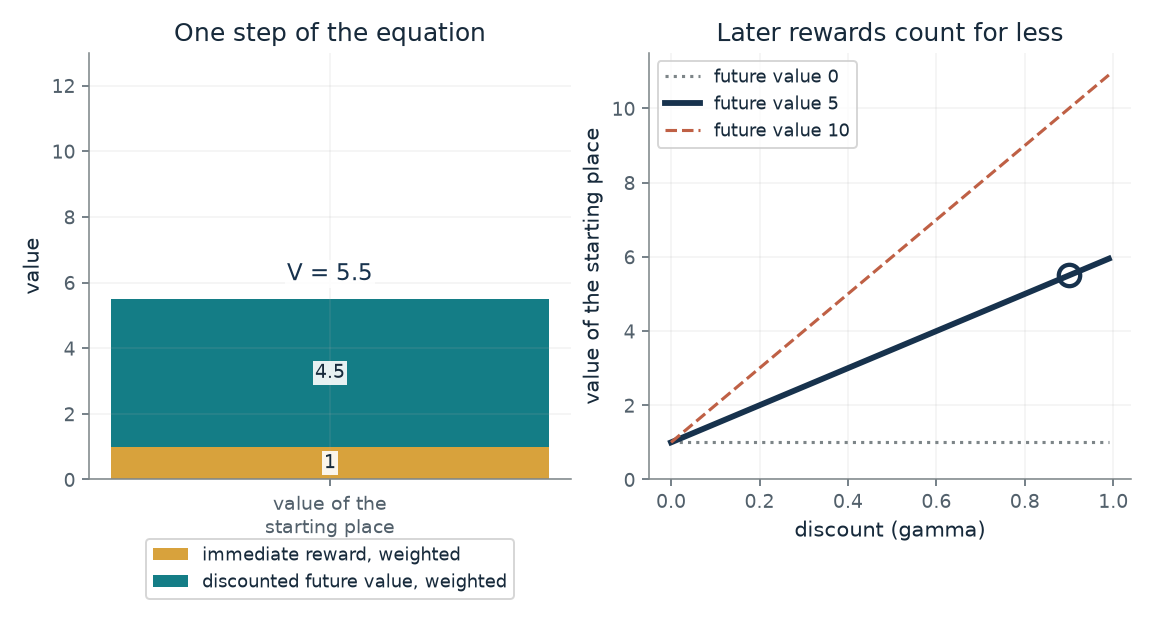

- **Value of the starting place:** 5.5
- **Immediate part:** 1
- **Discounted future part:** 4.5

The only reachable place pays 1 now and is worth 5 later; with discount 0.9 it adds 4.5, so the value is 5.5. Raising the discount makes the future count for more.

V = 1 x (1 + 0.9 x 5) + 0 x (0 + 0.9 x 0) = 5.5.

In [2]:
figure, values, explanation = value_picture(**{'gamma': 0.9, 'future_value': 5, 'reach': 1.0})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How does the value of a place come from what happens next?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Discount (gamma) = 0.9, Future value of the next place = 5, Chance of reaching that place = 1.0: With one possible next place, discount 0.9 and future value 5, the value is 1 + 0.9 x 5 = 5.5. The future supplies 4.5 of the 5.5, so most of the value is later.

**Takeaway:** A place is worth its immediate reward plus a discounted share of what lies beyond it, and a higher discount lets the future count for more.

**Why it matters:** A planner that holds a model of how places lead to one another can score any place by this equation once it is given a goal and a rule, without a new trip.

**In brains and behavior:** Tolman read the rats' sudden drop in errors as a cognitive map. The chapter says calling a map a transition model is a modern reading, not Tolman's, and the rat is not shown to hold this table.

**In machines:** An agent that stores a transition model and plans with it is called model-based. The equation is a specification of how such an agent scores a place under a fixed rule.

**Where it applies:** One fixed rule for choosing actions, known chances, a discount at least 0 and below 1, and a next-place value that is given. The equation evaluates the fixed movement rule; finding the best rule needs a comparison of actions. A rat's remembered route is not shown to be encoded in this table.

**Check your understanding:** A place pays 1 now and leads with certainty to a place worth 10. With discount 0.5, what is its value?

<details><summary>Show the answer</summary>

1 + 0.5 x 10 = 6.

</details>

*Source: Chapter 17, A map can be scored after the goal changes. Book equation and its worked example: one possible next place, immediate reward 1, future value 5, discount 0.9, giving 5.5. The other discounts, future values and the 0.6 chance of reaching the place are this companion's variations.*

## C17-D02: Why does A star explore B first and never touch C?

Which towns does a search explore on a four-town map, and what route does it return?

The search always explores the place with the lowest score, cost so far plus a guess of what is left. A guess that never runs too high means a place's score is a floor on any route through it, so once the goal has the lowest score no unexplored place can beat it. When the road from B to D is long enough, B's route to D stops being the cheapest and the search turns to C.

$$
f(n)=g(n)+h(n)
$$

**Symbols:** n: a place on the map; g(n): the cost of the best path found so far from the start to n, in miles; h(n): a guess at the cost from n to the goal; it must never exceed the true cost left and must equal zero at the goal; f(n): the score: cost so far plus the guess

**Predict before looking:** With the road from B to D at 6 miles and no road from C, predict which town is explored first and whether C is ever explored.

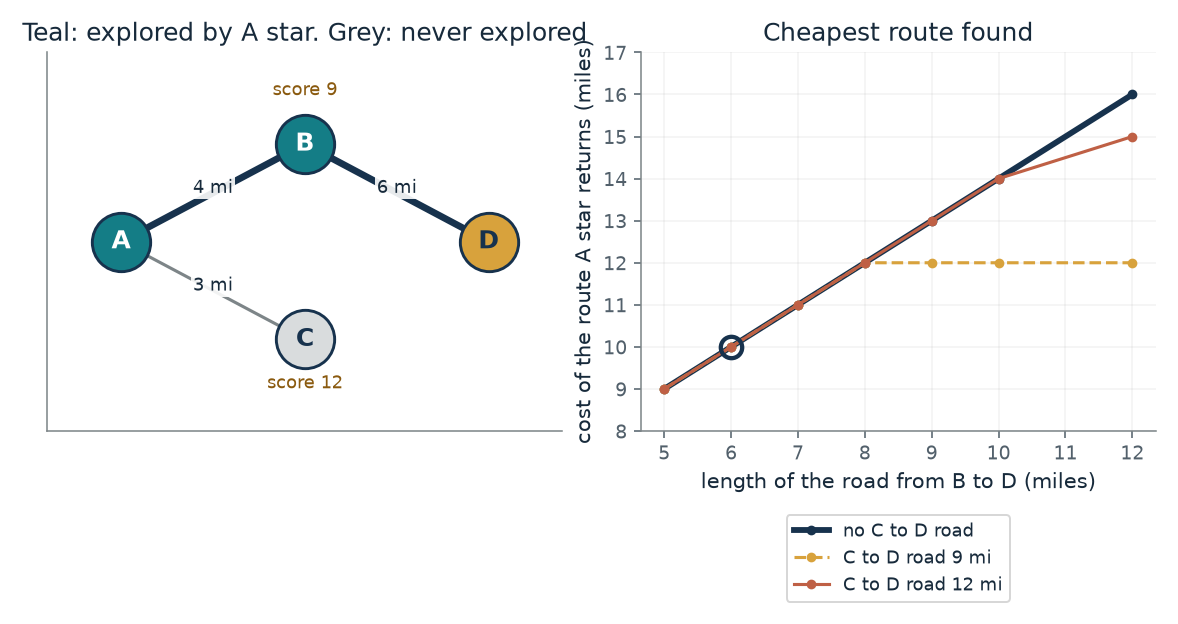

- **Route found:** A to B to D
- **Cost (miles):** 10
- **Places A star explored:** A, B
- **Places explored by cost so far alone:** A, C, B

A star returns A to B to D at 10 miles after exploring 2 places (A, B). Using cost so far alone, with no guess, explores 3 (A, C, B).

Score = miles so far + straight-line guess. B: 4 + 5 = 9. C: 3 + 9 = 12. Through B the route to D costs 4 + 6 = 10; there is no road from C to D in this map.

In [3]:
figure, values, explanation = town_picture(**{'bd_miles': 6, 'cd_miles': 0})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Why does A star explore B first and never touch C?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Length of the B to D road (miles) = 6, Road from C to D = 0: B scores 4 + 5 = 9 and C scores 3 + 9 = 12, so B is explored first. D is then reached at 4 + 6 = 10, below C's 12, so the search stops and C is never explored. Searching by cost so far alone explores C and B before reaching D.

**Takeaway:** The guess lets the search skip towns that cannot beat the route already found, and the first goal it takes from the list is a cheapest route.

**Why it matters:** Planning means running a model forward to see where actions lead, and every road leads to more roads. A good guess prunes the roads that cannot win without losing the best route.

**In brains and behavior:** A star is engineering proved on paper, built for machines. The chapter does not offer it as a model of how people or rats search.

**In machines:** A star is a specification with a proof: with a guess that never runs high, the route it returns is a cheapest one. Its authors note that exploring the fewest places might not minimize the total resources used.

**Where it applies:** A finite map with nonnegative road costs, guesses that never exceed the true cost left and equal zero at the goal, and a search that may reopen a place when it finds a cheaper way there. A star was built for machines and is not a model of how people search.

**Check your understanding:** With the B to D road at 12 miles and a 9 mile road from C to D, which route does A star return, and what does it cost?

<details><summary>Show the answer</summary>

Through B the route would cost 4 + 12 = 16, through C it costs 3 + 9 = 12. After exploring B (score 9), C (score 12) has the lowest score and its road to D gives 12, so the route is A, C, D at 12 miles.

</details>

*Source: Chapter 17, A town map and a score for every open road. Hart, Nilsson and Raphael (1968) as the chapter describes them, with the chapter's four-town map: A to B 4 miles, A to C 3 miles, B to D 6 miles, straight-line guesses 5 from B and 9 from C. The chapter gives no road from C to D; the optional C to D road and the other B to D lengths are this companion's variations, kept at least as long as the straight-line guesses so that those guesses never run too high.*

## C17-D03: What goes wrong if a search will not reopen a place?

A place is closed at one cost and a cheaper way to it turns up later. Does the search still return a cheapest route?

At first the search reaches A at cost 3 and B at cost 1. A scores 3, below B's score of 1 plus its guess. With the guess at B of 3, B scores 4, so A is explored first and closed. When B is explored, it offers A a cheaper cost of 2. A search that may reopen A takes it, and G is then reached at 4. One that cannot reopen keeps cost 3 for A and reaches G at 5.

$$
g(G)=f(G)\le f(n)\le C^{*}\le g(G)
$$

**Symbols:** G: the goal the search selects; n: an open place on an optimal route; C*: the cost of a cheapest route; f, g: score and cost so far; the chain holds when guesses never run high and cheaper ways to a place are reopened

**Predict before looking:** With the guess at B set to 3 and a search that never reopens a closed place, predict whether the route cost it returns is 4 or more.

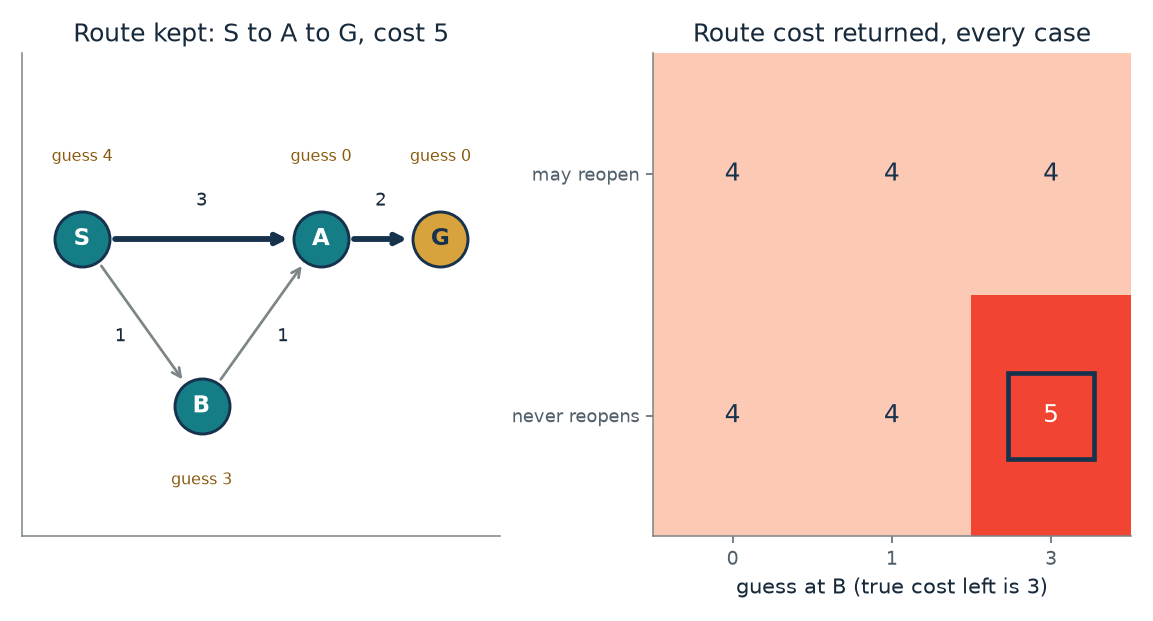

- **Cost returned:** 5
- **True cheapest cost:** 4
- **Places explored:** S, A, B
- **Search may reopen places:** no

With the guess at B set to 3 and reopening not allowed, the search returns a route costing 5; the cheapest is 4. A place that was closed early had a cheaper way found later and was never revisited.

Roads S to A 3, S to B 1, B to A 1, A to G 2. Cheapest route S, B, A, G costs 1 + 1 + 2 = 4. A scores 3 + 0 = 3 on first reach, while B scores 1 + 3 = 4; if A is closed first at cost 3 and never reopened, G is reached at 3 + 2 = 5.

In [4]:
figure, values, explanation = reopen_picture(**{'h_b': 3, 'reopen': 0})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='What goes wrong if a search will not reopen a place?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Guess of the cost left from B = 3, Search may reopen a place = 0: With the guess at B at 3 and no reopening, A is closed at cost 3 before B is explored. The cheaper way through B (cost 2 to A) is never used, and the search returns 5 instead of the cheapest 4. Allow reopening, or lower the guess at B to 1 or less, and the cost is 4.

**Takeaway:** A guess that never runs high is not enough on its own: when a guess is not consistent with the roads, a search must be allowed to revisit a place whose cost was lowered.

**Why it matters:** A guarantee has conditions. A planner that drops one of them, here by never reopening, can return a route that is worse than the best without any sign that it has.

**In machines:** This is a specification checked by tracing a small graph. Straight-line distance never needs reopening, so the chapter's town map is not affected.

**Where it applies:** A finite directed graph with nonnegative costs and guesses that never exceed the true cost left. The guess at S is not consistent with the roads, which is why the chapter's reopening condition matters. Straight-line distance never needs reopening; this made-up guess is not a straight-line distance.

**Check your understanding:** With the guess at B set to 1 and no reopening, which of A and B is explored first, and what does the search return?

<details><summary>Show the answer</summary>

B scores 1 + 1 = 2 and A scores 3, so B is explored first and gives A the cost 2 before A is closed. Reopening never comes up, and the search returns 4.

</details>

*Source: Chapter 17, A town map and a score for every open road. The constructed numeric check in the book's Derivation 16: roads S to A 3, S to B 1, B to A 1 and A to G 2, with guesses 4, 0, 3 and 0 at S, A, B and G. Reopening finds cost 4, and permanently closing gives 5. The other guesses at B are this companion's variations, kept at or below the true cost left (3).*

## C17-D04: Can a table of expected visits be re-scored when only the goal moves?

A walker steps right through three rooms and stops in room 3. If the reward moves from room 3 to room 2, what changes in the table and what changes in the values?

From room 1 the walker visits room 1 now, room 2 one step later and room 3 two steps later, and later visits count for less by the discount each step. Those weights depend only on the rule. Multiplying them by the rewards gives the value. Move the reward and only that multiplication changes.

$$
V(s)=\sum_{j} M(s,j)\,r(j),\qquad M=(I-\gamma P)^{-1}
$$

**Symbols:** M(s, j): the discounted visits to room j to expect when starting in room s under the fixed rule; P: the chance of stepping from one room to the next under the fixed rule (always right); r(j): the reward in room j (8 in one room, none elsewhere); gamma: the discount; later visits count for less

**Predict before looking:** Predict the value of room 1 when the 8 sits in room 3, and then when it moves to room 2, at a discount of one half.

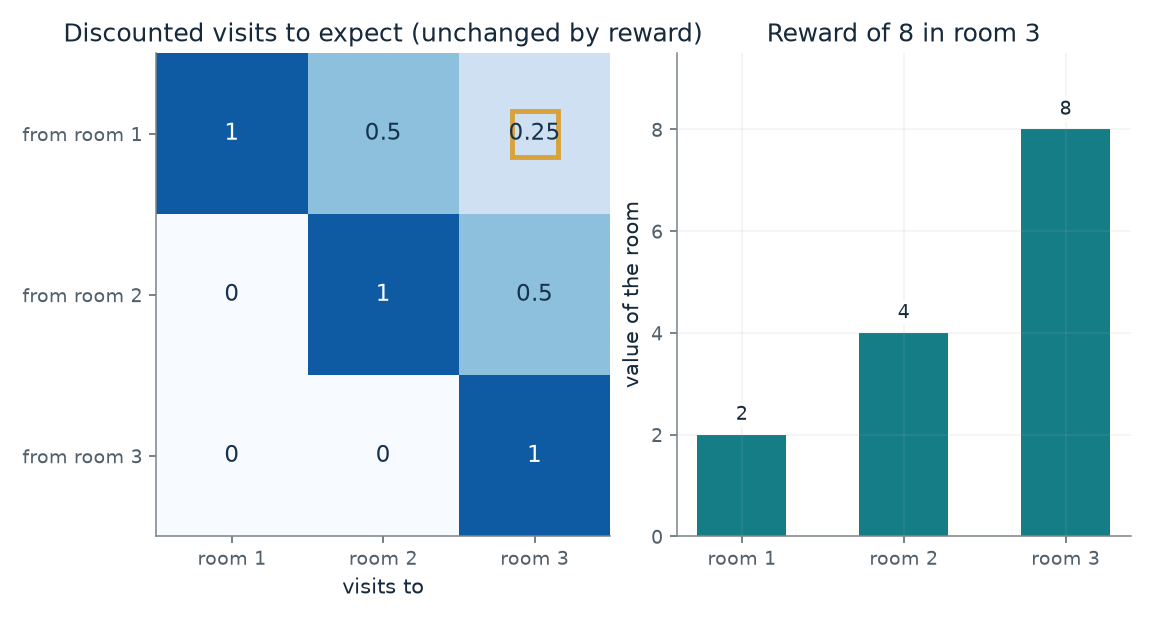

- **Value of room 1:** 2
- **Value of room 2:** 4
- **Value of room 3:** 8
- **Visit weights from room 1:** 1, 0.5, 0.25

With discount 0.5, the walker from room 1 expects visits worth 1, 0.5, 0.25 in rooms 1, 2 and 3. A reward of 8 in room 3 makes room 1 worth 2. Moving the reward changes the values without changing the table, and the walker still follows the old rule.

Value of room 1 = (visits from room 1) times (rewards) = 1 x 0 + 0.5 x 0 + 0.25 x 8 = 2.

In [5]:
figure, values, explanation = successor_picture(**{'reward_room': 3, 'gamma': 0.5})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Can a table of expected visits be re-scored when only the goal moves?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Room holding the reward of 8 = 2, Discount (gamma) = 0.5: The visit table is the same as before, with weights 1, 0.5 and 0.25 from room 1. Moving the reward from room 3 to room 2 raises the value of room 1 from 2 to 4 with no new walk. The walker still follows the old rule and continues to room 3.

**Takeaway:** A table of expected future visits, kept apart from the rewards, lets a new goal be scored at once, for the rule the table was built under.

**Why it matters:** Latent learning raises the question of how a layout could be kept so a new goal can be scored without new trips. This is one answer, with its limits: it assumes the rule stays fixed.

**In brains and behavior:** Dayan noted that filling in the table by exploring before reward 'can be viewed as a form of latent learning'. He did not call the table a map, and the rats are not shown to hold one.

**In machines:** A learner can store the table, keep it apart from rewards and re-score it when a reward moves, as long as it keeps following the same rule.

**Where it applies:** A fixed movement rule (always step right, stop in room 3) and a discount below 1. The table depends on the rule and is not 'a veridical map of the world', in Dayan's words. Re-scoring a fixed rule is not the same as finding a new best route.

**Check your understanding:** At discount 0.5, the reward of 8 is in room 1. What is the value of room 1, and does the table change?

<details><summary>Show the answer</summary>

8 x 1 = 8, because room 1 visits itself with weight 1. The table is the same: 1, 0.5 and 0.25 from room 1.

</details>

*Source: Chapter 17, Four rats and place cells that pictured the path ahead. Dayan's successor idea (1993) as the chapter describes it, with the chapter's three-room corridor: discount one half, visits 1, one half and one quarter from room 1, reward 8, giving values 2 (reward in room 3) and 4 (reward in room 2). The other discounts and reward rooms are this companion's variations; none of it is data.*

## C17-D05: Why can a first look be worth nothing while two looks pay?

A player can pass for a sure 0.75 or answer a coin-flip question. Hints are right 7 times in 10. What is each look worth?

One hint makes the player 70 percent sure, which is still below the sure 0.75, so the player passes and the hint changed nothing. Two hints agree on 58 of 100 questions, and then the favored answer is right on 49 of those 58. The player answers then and passes when the hints split, for 80.5 points per 100 questions against 75.

$$
\mathrm{Value}(k)=\sum_{m}P(m)\max\{0.75,\ P(\text{favored answer right}\mid m)\},\qquad \text{Gain}(k)=\mathrm{Value}(k)-0.75
$$

**Symbols:** k: the number of looks (hints) taken; m: how many of the k hints point at the true answer; P(m): the chance of that count, with answers equally likely and hints independent given the answer; 0.75: the sure points from passing; answering pays 1 if right and 0 if wrong

**Predict before looking:** At hint accuracy 0.7, predict the value of the first look, then of the second. Does a planner that prices only the next look take either?

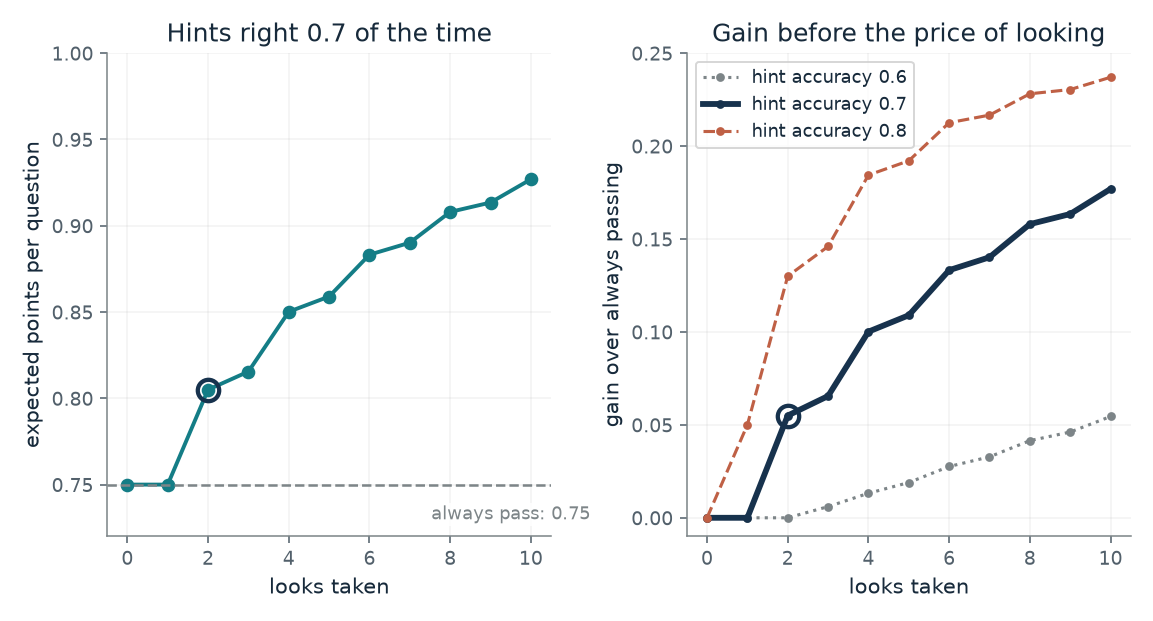

- **Expected points per question:** 0.805
- **Gain over always passing:** 0.055
- **Added by the last look:** 0.055
- **Price per look at which looking just pays:** 0.0275

After 2 looks with hints right 0.7 of the time, the player expects 0.805 points per question against 0.75 for passing, a gain of 0.055. The last look added 0.055.

Value of 2 looks = sum over hint counts of (chance of the count) x (larger of 0.75 and the chance the favored answer is right) = 0.805. Gain = 0.805 - 0.75 = 0.055. Break-even price per look = 0.055/2 = 0.0275.

In [6]:
figure, values, explanation = hint_counts_picture(**{'looks': 2, 'accuracy': 0.7})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Why can a first look be worth nothing while two looks pay?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Looks taken = 2, Chance each hint is right = 0.7: At accuracy 0.7 one look leaves the player 70 percent sure, still below 0.75, so it changes nothing and is worth 0. Two looks give 0.805 points per question, a gain of 0.055. A planner pricing only the next look stops before discovering that a second look pays.

**Takeaway:** A look can be worth nothing by itself and a lot together with another, so pricing only the next look can stop a planner too early.

**Why it matters:** Whether to keep searching depends on what later looks make possible. A planner that stops when the next look is worthless can miss that two looks together change the choice.

**In brains and behavior:** The chapter reports no study that measures how often one-step pricing misleads people; the quiz is a made-up illustration.

**In machines:** A builder chooses the search depth. At depth one the first look shows no gain; at depth two it shows a gross gain of 0.055 per question.

**Where it applies:** Independent hints given the correct answer, equally likely answers, a known pass payoff and a player who updates by Bayes' rule. If every look costs the same amount, looking pays only when that price is below the gain per look. No study here measures how often one-step pricing misleads real systems.

**Check your understanding:** At hint accuracy 0.8, is one look worth anything, and what is the value of two looks?

<details><summary>Show the answer</summary>

One look makes the player 80 percent sure, above 0.75, so answering pays 0.8 and the gain is 0.05. Two looks: agree on 0.68, right with chance 0.64/0.68, split on 0.32; value 0.64 + 0.32 x 0.75 = 0.88, a gain of 0.13.

</details>

*Source: Chapter 17, A first look worth nothing, two looks worth 0.055. The chapter's made-up quiz: pass pays 0.75, answering pays 1 or 0, equally likely answers, hints right 7 times in 10 and independent given the answer. One look is worth 0 and two are worth 0.055 (80.5 points per 100 questions). The other hint accuracies and the numbers of looks are this companion's variations. The chapter says the numbers are not findings.*

## C17-D06: How many looks does it take to find a move the model rates as rare?

If a search tries moves in proportion to a starting weight, how many looks does a one-in-ten-thousand move need before it is ever tried?

Each look is one draw. The chance that a given move is never drawn in n looks is (1 - w)^n, which shrinks only slowly when w is tiny. So a move with weight 0.0001 needs thousands of looks before it is probably tried, and a search with a smaller budget will probably never weigh it.

$$
P(\text{tried at least once})=1-(1-w)^{n},\qquad n_{c}=\left\lceil\frac{\ln(1-c)}{\ln(1-w)}\right\rceil
$$

**Symbols:** w: the starting weight the model gives a move (one in ten thousand is 0.0001); n: the number of independent looks; c: the chance wanted that the move is tried at least once; n_c: the least number of looks that gives chance c

**Predict before looking:** For a move with weight one in ten thousand, predict whether 1,000 looks give a better or worse than even chance of ever trying it.

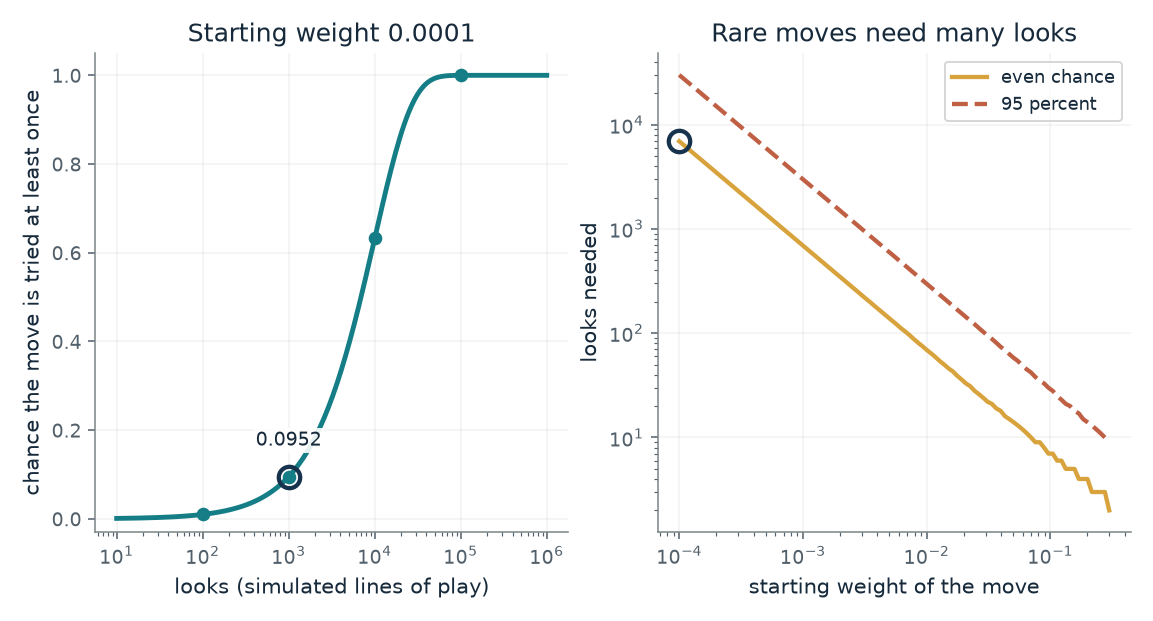

- **Chance the move is tried:** 0.0952
- **Looks for an even chance:** 6,932
- **Looks for 95 percent:** 29,956

A move given starting weight 0.0001 is tried at least once in 1,000 looks with chance 0.0952. It takes about 6,932 looks for an even chance. This toy draws moves in proportion to their weight; it is not AlphaGo's algorithm.

Chance = 1 - (1 - w)^n = 1 - (1 - 0.0001)^1000 = 0.0952. Looks for chance c: n = ln(1 - c)/ln(1 - w).

In [7]:
figure, values, explanation = blind_spot_picture(**{'weight': 0.0001, 'looks': 1000})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How many looks does it take to find a move the model rates as rare?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Starting weight of the move = 0.0001, Looks (simulated lines of play) = 1000: With weight 0.0001 and 1,000 looks, the chance of trying the move even once is about 0.095. It takes about 6,932 looks for an even chance and about 29,956 for 95 percent. A search can only weigh the futures its model holds.

**Takeaway:** A move the model rates as very rare can go unexamined for a long time, and a search that never examines it cannot weigh what it would bring.

**Why it matters:** A planner can only weigh the futures its model holds. If the model rates a move as nearly impossible, the omission travels through the search however carefully it is steered.

**In brains and behavior:** No brain data are involved. The chapter says the evidence on Seoul does not show the cause of the mistake.

**In machines:** In the 2016 match, the program met a move it had put at about one in ten thousand for a human, and by Hassabis's account its own win estimate fell only at about move 87 (from about 70 percent at move 79). The toy shows why a rare move can stay unexamined; it does not explain this game.

**Where it applies:** Each look draws one move independently with chance equal to its weight. A real tree search also uses the results of earlier looks and a value estimate, and the accounts cited do not establish why the program erred at move 79 or what its policy network and search did. This is one game and one move; it shows what a search can miss, not how often it does.

**Check your understanding:** A move has weight 0.01. How many looks give at least a 95 percent chance of trying it at least once?

<details><summary>Show the answer</summary>

n = ln(0.05)/ln(0.99) = 298.07, so 299 looks.

</details>

*Source: Chapter 17, Move 79, and a value estimate that dived on move 87. The reported figure is Hassabis's statement, as Wired reports it, that by AlphaGo's own estimate there was about one chance in ten thousand that a human would play move 78. No source read says how the program reached that number. The calculation is a toy this companion built: independent draws in proportion to a starting weight. It is not AlphaGo's search, whose Seoul version may differ from the 2015 version in the Nature paper.*

## Bring it to your own question

Ask what the model holds, what the score ranks, and what each look costs. Work a value or a route score by hand on a small map before trusting a search, check whether a first look can look worthless while two looks pay, and ask a planner to list the constraints it assumed so that missing ones show. A search can only weigh the futures its model contains.

Use the `mmi-ch17-considering-future` skill to choose a relevant equation, work with your inputs, and interpret the result. The skill should explain the assumptions and distinguish an illustration from evidence about your particular situation.